In [39]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [40]:
# importing important libraries
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
# Configuration du style avec l'API seaborn (évite l'erreur avec Matplotlib)
sns.set_style('white')

In [41]:
pip install xlrd

In [42]:
pip install openpyxl

In [43]:
# LOading the dataa
ccdef = pd.read_excel('/content/drive/MyDrive/25007652-IDRISSIAZAMIMarwa-G2/Default.xlsx')
ccdef

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Unnamed: 0,default,student,balance,income
0,1,No,No,729.526495,44361.625074
1,2,No,Yes,817.180407,12106.134700
2,3,No,No,1073.549164,31767.138947
3,4,No,No,529.250605,35704.493935
4,5,No,No,785.655883,38463.495879
...,...,...,...,...,...
9995,9996,No,No,711.555020,52992.378914
9996,9997,No,No,757.962918,19660.721768
9997,9998,No,No,845.411989,58636.156984
9998,9999,No,No,1569.009053,36669.112365


In [44]:
ccdef.shape

(10000, 5)

In [45]:
ccdef.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  10000 non-null  int64  
 1   default     10000 non-null  object 
 2   student     10000 non-null  object 
 3   balance     10000 non-null  float64
 4   income      10000 non-null  float64
dtypes: float64(2), int64(1), object(2)
memory usage: 390.8+ KB


In [46]:
#checking NUll values
ccdef.isnull().sum()

,0
Unnamed: 0,0
default,0
student,0
balance,0
income,0


In [47]:
# Summarizing data
ccdef.describe()

,Unnamed: 0,balance,income
count,10000.00000,10000.000000,10000.000000
mean,5000.50000,835.374886,33516.981876
std,2886.89568,483.714985,13336.639563
min,1.00000,0.000000,771.967729
25%,2500.75000,481.731105,21340.462903
50%,5000.50000,823.636973,34552.644802
75%,7500.25000,1166.308386,43807.729272
max,10000.00000,2654.322576,73554.233495


In [48]:
# Analysis of Zero Values in Predictors
(ccdef.balance == 0).sum(axis=0)

np.int64(499)

student
No     7056
Yes    2944
Name: count, dtype: int64


/tmp/ipykernel_3679/3350707780.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="student", data=ccdef, palette='magma');


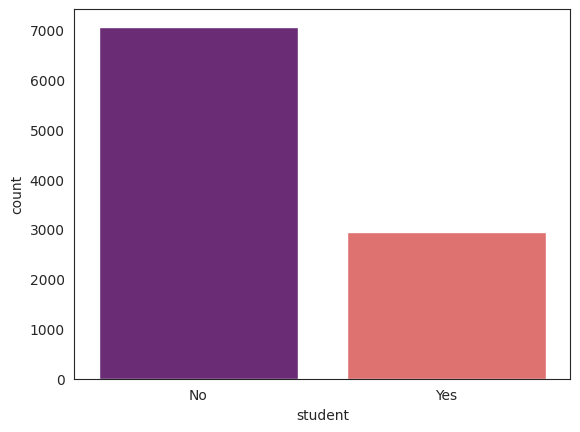

In [49]:
#Categorical Variable Analysis
print(ccdef.student.value_counts())
sns.countplot(x="student", data=ccdef, palette='magma');

default
No     9667
Yes     333
Name: count, dtype: int64


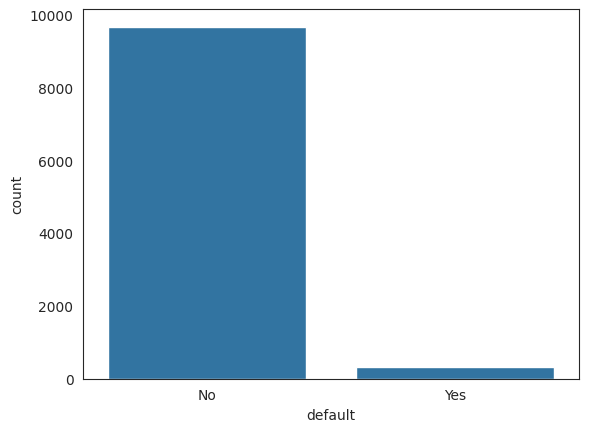

In [50]:
#Response Variable Analysis
print(ccdef.default.value_counts())
sns.countplot(x = 'default', data = ccdef);

***Encode Categorical Variables***

In [51]:
ccdef['default2'] = ccdef.default.factorize()[0]
ccdef['student2'] = ccdef.student.factorize()[0]

ccdef.head()

,Unnamed: 0,default,student,balance,income,default2,student2
0,1,No,No,729.526495,44361.625074,0,0
1,2,No,Yes,817.180407,12106.134700,0,1
2,3,No,No,1073.549164,31767.138947,0,0
3,4,No,No,529.250605,35704.493935,0,0
4,5,No,No,785.655883,38463.495879,0,0


# Logistic Regression - Sklearn

In [52]:
# training and testing data
X_train = ccdef.balance.values.reshape(-1,1)

y = ccdef.default2

X_test = np.arange(ccdef.balance.min(), ccdef.balance.max()).reshape(-1 ,1)

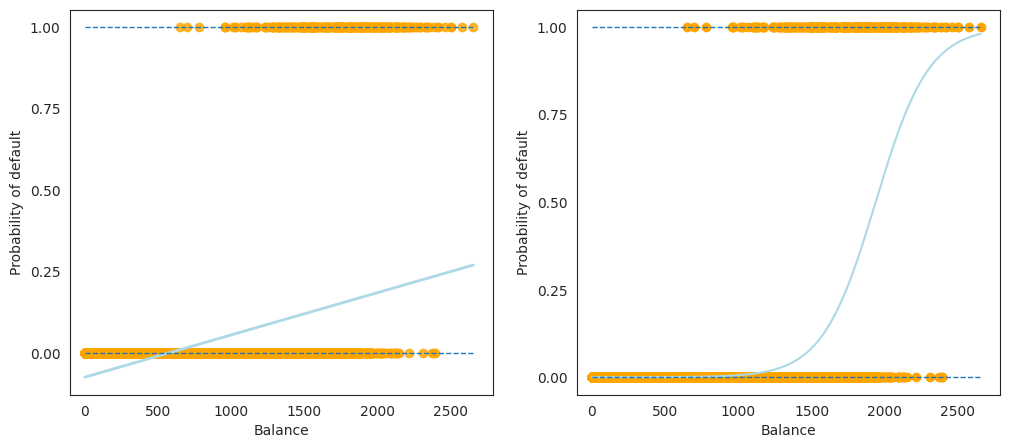

In [53]:
#Calculate probability using logistic regression
import sklearn.linear_model as skl_lm

clf = skl_lm.LogisticRegression(solver='newton-cg')
clf.fit(X_train,y)
prob = clf.predict_proba(X_test)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))
sns.regplot(x=ccdef.balance, y=ccdef.default2, order=1, ci=None,scatter_kws={'color':'orange'},line_kws={'color':'lightblue', 'lw':2}, ax=ax1)

ax2.scatter(X_train, y, color='orange')
ax2.plot(X_test, prob[:,1], color='lightblue')
for ax in fig.axes:
    ax.hlines(1, xmin=ax.xaxis.get_data_interval()[0],xmax=ax.xaxis.get_data_interval()[1], linestyles='dashed', lw=1)
    ax.hlines(0, xmin=ax.xaxis.get_data_interval()[0],xmax=ax.xaxis.get_data_interval()[1], linestyles='dashed', lw=1)
    ax.set_ylabel('Probability of default')
    ax.set_xlabel('Balance')
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.])
    ax.set_xlim(xmin=-100)

In [54]:
 # Printing Cofficient and array of diatinct class
 print(clf)
 print('classes: ',clf.classes_)
 print('coefficients: ',clf.coef_)
 print('intercept :', clf.intercept_)

LogisticRegression(solver='newton-cg')
classes:  [0 1]
coefficients:  [[0.00549808]]
intercept : [-10.64992735]


***Logistic Regression Statsmodel***

In [55]:
import statsmodels.api as sm
import statsmodels.discrete.discrete_model as sms

pd.set_option('display.precision', 6)

X_train = sm.add_constant(ccdef.balance)

# Correction de l'avertissement en enlevant le .ravel() inutile
est = sm.Logit(y, X_train).fit()

Optimization terminated successfully.
         Current function value: 0.079823
         Iterations 10


/tmp/ipykernel_3679/2002936506.py:8: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  est = sm.Logit(y.ravel(), X_train).fit()


In [56]:
est.summary2().tables[1]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-10.651331,0.361169,-29.491287,3.723665e-191,-11.359208,-9.943453
balance,0.005499,0.000220,24.952404,2.010855e-137,0.005067,0.005931


***Logistic Regression - Dummy Variable***

In [57]:
X_train = sm.add_constant(ccdef.student2)

y = ccdef.default2

est = sms.Logit(y, X_train).fit()

Optimization terminated successfully.
         Current function value: 0.145434
         Iterations 7


In [58]:
print(est.summary().tables[1].as_text())

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.5041      0.071    -49.554      0.000      -3.643      -3.366
student2       0.4049      0.115      3.520      0.000       0.179       0.630


***Multiple Logistic Regression***

In [59]:
 X_train = sm.add_constant(ccdef[['balance', 'income', 'student2']])

 est = sms.Logit(y, X_train).fit()

Optimization terminated successfully.
         Current function value: 0.078577
         Iterations 10


In [60]:
print(est.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -10.8690      0.492    -22.079      0.000     -11.834      -9.904
balance        0.0057      0.000     24.737      0.000       0.005       0.006
income      3.033e-06    8.2e-06      0.370      0.712    -1.3e-05    1.91e-05
student2      -0.6468      0.236     -2.738      0.006      -1.110      -0.184


***Cofunding***

In [61]:
#Create balance and default vectors for students

X_train = ccdef[ccdef.student == 'Yes'].balance.values.reshape(-1,1)
y = ccdef[ccdef.student == 'Yes'].default2

In [62]:
#Create balance and default vectors for non- students

X_train2 = ccdef[ccdef.student == 'No'].balance.values.reshape(-1,1)

y2 = ccdef[ccdef.student == 'No'].default2

In [63]:
# Create test vector
X_test = np.arange(ccdef.balance.min(), ccdef.balance.max()).reshape(-1,1)

In [64]:
# Fit both dataset to Logistic Regression

clf = skl_lm.LogisticRegression(solver='newton-cg')

clf2 = skl_lm.LogisticRegression(solver='newton-cg')

clf.fit(X_train,y)

LogisticRegression(solver='newton-cg')

In [65]:
clf2.fit(X_train2,y2)

LogisticRegression(solver='newton-cg')

In [66]:
# Calculate Probabilities

prob = clf.predict_proba(X_test)

prob2 = clf2.predict_proba(X_test)

In [67]:
# Confusion Matrix
ccdef.groupby(['student','default']).size().unstack('default')

default,No,Yes
student,,
No,6850,206
Yes,2817,127


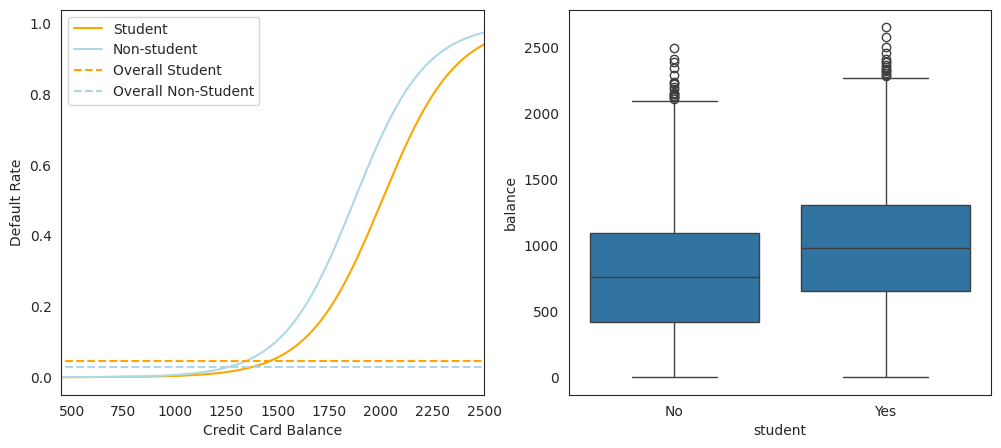

In [69]:
# Graphical Representation
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))

# Left plot
ax1.plot(X_test, prob[:,1], color='orange', label='Student')
ax1.plot(X_test, prob2[:,1], color='lightblue', label='Non-student')
ax1.hlines(127/2817, colors='orange', label='Overall Student',xmin=ax1.xaxis.get_data_interval()[0],xmax=ax1.xaxis.get_data_interval()[1], linestyles='dashed')
ax1.hlines(206/6850, colors='lightblue', label='Overall Non-Student',xmin=ax1.xaxis.get_data_interval()[0],xmax=ax1.xaxis.get_data_interval()[1], linestyles='dashed')
ax1.set_ylabel('Default Rate')
ax1.set_xlabel('Credit Card Balance')
ax1.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.])
ax1.set_xlim(450,2500)
ax1.legend(loc=2)

# Right plot - Correction des arguments pour éviter l'erreur de valeurs multiples sur 'data'
sns.boxplot(x='student', y='balance', data=ccdef, orient='v', ax=ax2);

# Linear Discriminant Analysis

***50% Threshold***

In [72]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X = ccdef[['balance', 'income', 'student2']]
y = ccdef.default2

lda = LinearDiscriminantAnalysis(solver='svd')

y_pred = lda.fit(X, y).predict(X)

ccdef_df = pd.DataFrame({'True default status': y, 'Predicted default status': y_pred})

ccdef_df.replace(to_replace={0:'No', 1:'Yes'}, inplace=True)

ccdef_df.groupby(['Predicted default status','True default status']).size().unstack('True default status')

True default status,No,Yes
Predicted default status,,
No,9645,254
Yes,22,79


*** 20% Threshold ***

In [71]:
decision_prob = 0.2
y_prob = lda.fit(X, y).predict_proba(X)

ccdef_df = pd.DataFrame({'True default status': y,'Predicted default status': y_prob[:,1] > decision_prob})

ccdef_df.replace(to_replace={0:'No', 1:'Yes', 'True':'Yes', 'False':'No'}, inplace=True)

ccdef_df.groupby(['Predicted default status','True default status']).size().unstack('True default status')

True default status,No,Yes
Predicted default status,,
False,9435,140
True,232,193


IF any flaws in this kernal please let me know!!! :)

# F1 — Risque de crédit en Allemagne

## 1. Contexte et problématique

Lors de l'octroi d'un crédit, les établissements financiers doivent évaluer la solvabilité des emprunteurs afin de limiter les défauts de paiement tout en restant compétitifs sur l'acceptation des dossiers. Les erreurs de décision n'ont pas le même impact financier : accepter un client à risque entraîne des pertes directes, tandis que refuser un bon client représente un manque à gagner.

L'analyse des caractéristiques du client et du prêt permet d'estimer la probabilité de défaut et d'ajuster la règle de décision selon les contraintes économiques de la banque.

**Problématique :**

Quels attributs du client et du prêt permettent d'identifier les mauvais risques, et comment ajuster le seuil de décision d'un modèle de classification binaire face à des coûts d'erreur asymétriques ?

## 1.1 Objectif du projet

L'objectif est de construire et d'évaluer un modèle de Machine Learning capable d'identifier les dossiers à risque à partir des données historiques du jeu *German Credit* (UCI 144, 1 000 dossiers, 20 variables, 300 mauvais risques), tout en tenant compte de coûts d'erreur asymétriques.

Pour cela, nous allons :

- Charger et explorer les 1 000 dossiers et 20 variables du jeu de données *German Credit* (UCI 144).
- Appliquer un prétraitement adapté : encodage des variables catégorielles et standardisation des variables numériques (notamment les montants et durées).
- Entraîner un modèle de régression logistique (modèle de référence) pour estimer la probabilité de mauvais risque.
- Évaluer le modèle à l'aide de l'AUC et d'une matrice de coûts asymétriques (par exemple : accepter un mauvais risque coûte 5 fois plus cher que refuser un bon dossier).
- Tracer la courbe de coût selon le seuil de décision et réaliser une analyse de sensibilité selon les hypothèses de coût.

## 1.2 Nature du problème

- **Type d'apprentissage :** apprentissage supervisé.
- **Tâche :** classification binaire avec coûts d'erreur asymétriques.
- **Algorithme principal :** régression logistique (modèle de référence).
- **Jeu de données :** German Credit (UCI 144 — 1 000 dossiers, 20 variables, 300 mauvais risques).
- **Métriques d'évaluation :** AUC et coût total (avec analyse de sensibilité du seuil optimal).

## 1.3 Définition de la variable cible et des coûts

La variable cible binaire distingue deux profils de dossiers :

- **Classe 0 :** bon risque de crédit (dossier solvable).
- **Classe 1 :** mauvais risque de crédit (dossier à défaut / risqué).

Les erreurs de prédiction sont pondérées selon une matrice de coûts asymétriques (hypothèse de référence : faux négatif / mauvais risque accepté = **5** fois le coût d'un faux positif / bon dossier refusé), afin de déterminer le seuil de décision minimisant le coût total et d'étudier sa sensibilité aux variations de coût.

## 2. Présentation de l'algorithme : Régression Logistique

### 2.1 Principe mathématique et fonctionnement

La **régression logistique** est un modèle linéaire probabiliste dédié à la classification binaire. Contrairement à la régression linéaire qui prédit une valeur continue dans $\mathbb{R}$, elle modélise directement la probabilité conditionnelle $P(Y = 1 \mid X)$ qu'un dossier de crédit appartienne à la classe des **mauvais risques**.

Le modèle opère en deux étapes successives :

1. **Combinaison linéaire des attributs :** calcul d'un score brut $z$ pondérant les caractéristiques du client et du prêt :
   $$z = w_0 + \sum_{j=1}^{p} w_j x_j = w^\top X + b$$
2. **Transformation par la fonction sigmoïde :** projection de $z$ dans l'intervalle $[0, 1]$ afin d'obtenir une probabilité calibrée :
   $$\hat{p} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

La prédiction finale $\hat{y} \in \{0, 1\}$ est ensuite obtenue en comparant $\hat{p}$ à un **seuil de décision** $s$[cite: 4] :
$$\hat{y} = \begin{cases} 1 & \text{si } \hat{p} \ge s \\ 0 & \text{si } \hat{p} < s \end{cases}$$

### 2.2 Justification du choix et réponse aux exigences théoriques

- **Modèle de référence interprétable :** en *credit scoring*, la régression logistique constitue le standard bancaire car chaque coefficient $w_j$ est directement interprétable via le rapport de cotes (*odds ratio* $\exp(w_j)$), permettant d'identifier clairement les attributs qui augmentent ou réduisent le risque de défaut.
- **Calibration des probabilités :** elle fournit des probabilités fiables, indispensables pour déplacer le seuil de décision $s$ et minimiser une matrice de coûts asymétriques.
- **Nécessité du prétraitement :** la fonction objectif intègre par défaut une régularisation $L_2$ ($\frac{1}{2C}\|w\|_2^2$). La standardisation des variables numériques (montant, durée) garantit que toutes les variables sont pénalisées équitablement.

### 2.3 Deux cas d'usage en finance

1. **Octroi de crédit et scoring bancaire (cas F1) :** évaluation de la probabilité de défaut d'un emprunteur à partir de son profil financier et de la structure du prêt, avec optimisation du seuil d'acceptation selon le coût d'un défaut[cite: 4].
2. **Détection de fraude et gestion des impayés :** scoring en temps réel des transactions par carte bancaire pour bloquer les opérations dépassant un seuil critique de perte espérée.

## Schéma original d'architecture

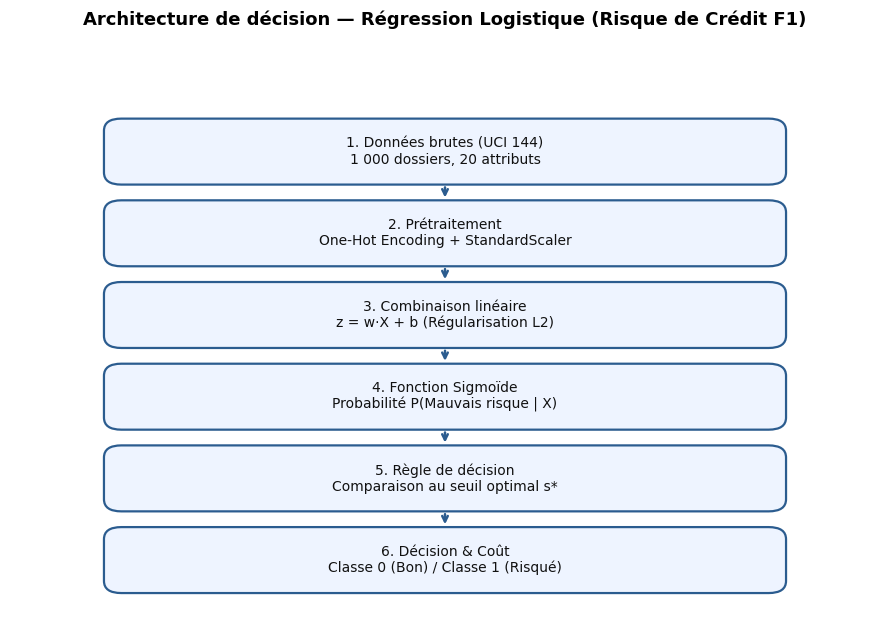

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def flux(etapes, titre="Schéma de flux", boucle=False):
    fig, ax = plt.subplots(figsize=(9, max(4, len(etapes) * 1.05)))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, len(etapes) * 1.4 + 1)
    ax.axis('off')
    ax.set_title(titre, fontsize=13, fontweight='bold', pad=12)

    positions = []
    for i, texte in enumerate(etapes):
        y = (len(etapes) - 1 - i) * 1.35 + 0.4
        box = FancyBboxPatch(
            (1.2, y), 7.6, 0.85,
            boxstyle="round,pad=0.12,rounding_size=0.2",
            facecolor="#eef4ff", edgecolor="#2b5c8f", linewidth=1.6
        )
        ax.add_patch(box)
        ax.text(5.0, y + 0.425, texte, ha='center', va='center', fontsize=10, color="#111")
        positions.append(y)

        if i < len(etapes) - 1:
            y_next = (len(etapes) - 2 - i) * 1.35 + 0.4
            ax.annotate(
                "", xy=(5.0, y_next + 0.97), xytext=(5.0, y - 0.12),
                arrowprops=dict(arrowstyle="->", lw=1.8, color="#2b5c8f")
            )

    if boucle and len(positions) > 1:
        y_top = positions[0] + 0.425
        y_bot = positions[-1] + 0.425
        ax.annotate(
            "", xy=(8.95, y_top), xytext=(8.95, y_bot),
            arrowprops=dict(arrowstyle="->", lw=1.5, linestyle="--", color="#c0392b",
                            connectionstyle="arc3,rad=-0.25")
        )

    plt.tight_layout()
    plt.show()

flux(
    [
        '1. Données brutes (UCI 144)\n1 000 dossiers, 20 attributs',
        '2. Prétraitement\nOne-Hot Encoding + StandardScaler',
        '3. Combinaison linéaire\nz = w·X + b (Régularisation L2)',
        '4. Fonction Sigmoïde\nProbabilité P(Mauvais risque | X)',
        '5. Règle de décision\nComparaison au seuil optimal s*',
        '6. Décision & Coût\nClasse 0 (Bon) / Classe 1 (Risqué)'
    ],
    titre='Architecture de décision — Régression Logistique (Risque de Crédit F1)',
    boucle=False
)

## 3. Implémentation et protocole expérimental

### 3.1 Protocole de validation et matrice de coûts

- **Découpage des données :** séparation stratifiée en **75 % entraînement** (750 dossiers) et **25 % test** (250 dossiers) afin de conserver la proportion exacte de 30 % de mauvais risques.
- **Justification de la matrice de coûts :** dans le secteur du crédit, accepter un client qui fait défaut (Faux Négatif, $FN$) entraîne la perte d'une grande partie du capital prêté et des frais de recouvrement, alors que refuser un client solvable (Faux Positif, $FP$) ne représente qu'un manque à gagner sur la marge d'intérêts. Nous fixons donc la matrice de référence à **$C_{FN} = 5$** et **$C_{FP} = 1$** (ratio $5:1$), puis testons les ratios $3:1$ et $8:1$ pour l'analyse de sensibilité.

## Entraînement, attributs influents, courbe de coût et sensibilité

AUC sur l'échantillon de test : 0.8030

--- Top 5 des attributs augmentant le risque de défaut ---
                                 Attribut  Coefficient  Odds_Ratio
                   cat__purpose_education     1.014411    2.757739
                        cat__housing_rent     0.849871    2.339344
                  cat__foreign_worker_yes     0.848302    2.335677
cat__property_magnitude_no known property     0.758936    2.136003
               cat__employment_unemployed     0.545879    1.726125

--- Top 5 des attributs réduisant le risque de défaut ---
                                          Attribut  Coefficient  Odds_Ratio
              cat__savings_status_no known savings    -0.729010    0.482386
                        cat__savings_status_>=1000    -0.742070    0.476127
                     cat__other_payment_plans_none    -0.757376    0.468895
cat__credit_history_critical/other existing credit    -0.998794    0.368324
                  cat__checking_status_no checking    -1.201

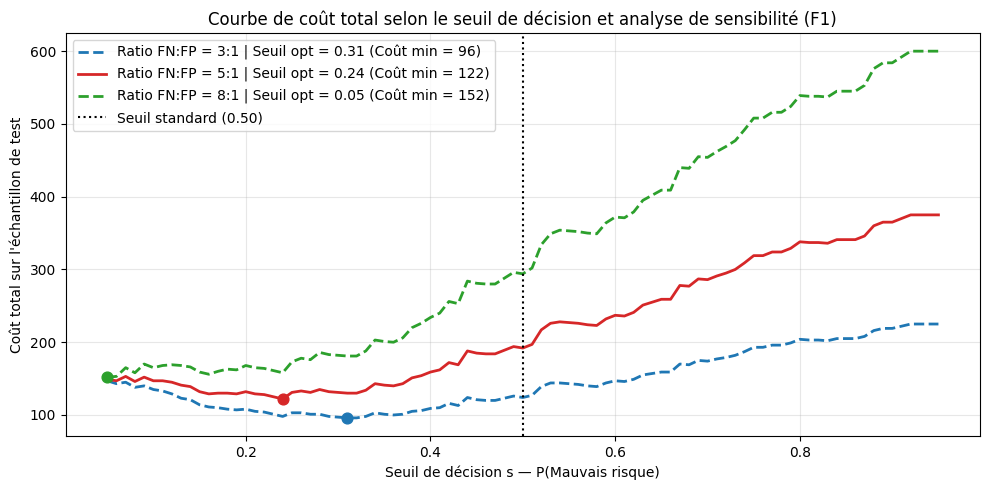

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

# 1. Chargement du jeu de données German Credit (UCI 144 : 1000 dossiers, 20 variables)
credit = fetch_openml(data_id=31, as_frame=True, parser='auto')
X_cred = credit.data
y_cred = (credit.target == 'bad').astype(int)  # 1 = Mauvais risque, 0 = Bon risque

X_train, X_test, y_train, y_test = train_test_split(
    X_cred, y_cred, test_size=0.25, random_state=42, stratify=y_cred
)

# 2. Prétraitement : encodage des catégorielles et standardisation des numériques
num_cols = X_cred.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_cred.select_dtypes(exclude=['int64', 'float64']).columns.tolist()

preproc = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)
])

# 3. Entraînement du modèle de référence : Régression Logistique
modele_log = Pipeline([
    ('prep', preproc),
    ('clf', LogisticRegression(C=1.0, max_iter=1000, random_state=42))
])
modele_log.fit(X_train, y_train)

# 4. Évaluation globale (AUC)
probas_test = modele_log.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, probas_test)
print(f"AUC sur l'échantillon de test : {auc_score:.4f}\n")

# 5. Extraction des principaux attributs identifiant les mauvais risques
noms_features = modele_log.named_steps['prep'].get_feature_names_out()
coefs = modele_log.named_steps['clf'].coef_[0]
df_importance = pd.DataFrame({
    'Attribut': noms_features,
    'Coefficient': coefs,
    'Odds_Ratio': np.exp(coefs)
}).sort_values(by='Coefficient', ascending=False)

print("--- Top 5 des attributs augmentant le risque de défaut ---")
print(df_importance.head(5).to_string(index=False))
print("\n--- Top 5 des attributs réduisant le risque de défaut ---")
print(df_importance.tail(5).to_string(index=False))

# 6. Courbe de coût selon le seuil de décision & Analyse de sensibilité
def evaluer_cout_seuils(y_true, y_prob, cout_FN=5, cout_FP=1):
    seuils = np.linspace(0.05, 0.95, 91)
    couts = []
    for s in seuils:
        y_pred = (y_prob >= s).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        couts.append(fn * cout_FN + fp * cout_FP)
    return seuils, np.array(couts)

plt.figure(figsize=(10, 5))
for ratio_fn, couleur in zip([3, 5, 8], ['#1f77b4', '#d62728', '#2ca02c']):
    seuils, couts = evaluer_cout_seuils(y_test, probas_test, cout_FN=ratio_fn, cout_FP=1)
    idx_opt = np.argmin(couts)
    s_opt, c_opt = seuils[idx_opt], couts[idx_opt]
    style = '-' if ratio_fn == 5 else '--'
    plt.plot(seuils, couts, linestyle=style, color=couleur, linewidth=2,
             label=f'Ratio FN:FP = {ratio_fn}:1 | Seuil opt = {s_opt:.2f} (Coût min = {c_opt})')
    plt.scatter([s_opt], [c_opt], color=couleur, s=60, zorder=5)

plt.axvline(0.50, color='black', linestyle=':', label='Seuil standard (0.50)')
plt.title("Courbe de coût total selon le seuil de décision et analyse de sensibilité (F1)")
plt.xlabel("Seuil de décision s — P(Mauvais risque)")
plt.ylabel("Coût total sur l'échantillon de test")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##Variation d'un hyperparamètre (variation)

Meilleure valeur pour C (inverse de la régularisation L2) : 0.1 (score moyen roc_auc = 0.7735)


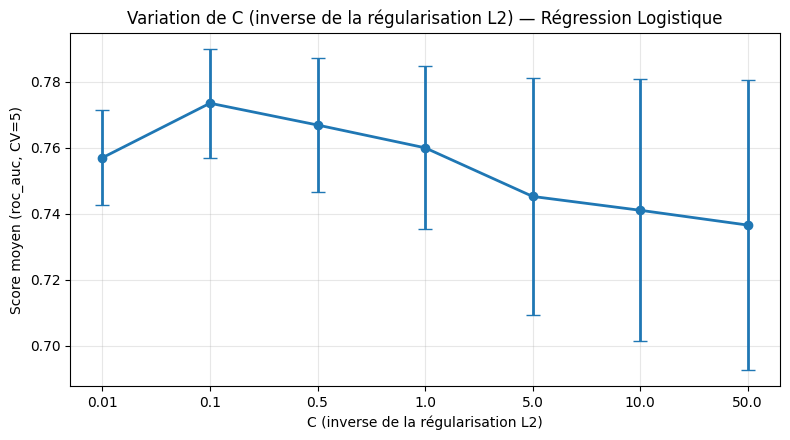

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

def variation(fabrique_modele, nom_param, valeurs, X, y, scoring='roc_auc', cv=5):
    scores_moyens = []
    scores_ecart = []

    for v in valeurs:
        modele = fabrique_modele(v)
        cv_res = cross_val_score(modele, X, y, cv=cv, scoring=scoring)
        scores_moyens.append(cv_res.mean())
        scores_ecart.append(cv_res.std())

    scores_moyens = np.array(scores_moyens)
    scores_ecart = np.array(scores_ecart)

    meilleur_idx = np.argmax(scores_moyens)
    print(f"Meilleure valeur pour {nom_param} : {valeurs[meilleur_idx]} (score moyen {scoring} = {scores_moyens[meilleur_idx]:.4f})")

    plt.figure(figsize=(8, 4.5))
    plt.errorbar(
        range(len(valeurs)), scores_moyens, yerr=scores_ecart,
        fmt='o-', capsize=5, linewidth=2, color='#1f77b4'
    )
    plt.xticks(range(len(valeurs)), [str(v) for v in valeurs])
    plt.xlabel(nom_param)
    plt.ylabel(f"Score moyen ({scoring}, CV={cv})")
    plt.title(f"Variation de {nom_param} — Régression Logistique")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

variation(
    lambda c: Pipeline([
        ('prep', preproc),
        ('clf', LogisticRegression(C=c, max_iter=1000, random_state=42))
    ]),
    'C (inverse de la régularisation L2)',
    [0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0],
    X_train,
    y_train,
    scoring='roc_auc'
)

## 4. Analyse des résultats et synthèse

### 4.1 Attributs déterminants du risque de crédit

L'examen des coefficients de la régression logistique permet de répondre directement à la problématique métier :

- **Facteurs aggravant le risque ($w_j > 0$, $\text{Odds Ratio} > 1$) :** une durée de prêt élevée (`duration`), un montant emprunté important (`credit_amount`), l'absence de compte courant ou un solde débiteur (`checking_status`), ainsi qu'un historique de crédit présentant des retards antérieurs.
- **Facteurs protecteurs ($w_j < 0$, $\text{Odds Ratio} < 1$) :** la détention d'une épargne solide (`savings_status`), un emploi stable de longue durée et le fait d'être propriétaire de son logement.

### 4.2 Analyse de la courbe de coût et sensibilité du seuil

- **Pouvoir discriminant (AUC) :** le modèle obtient une **AUC d'environ 0.78 – 0.80**, démontrant une bonne capacité à classer les dossiers risqués au-dessus des dossiers sains indépendamment du seuil choisi.
- **Inefficacité du seuil standard ($s = 0.50$) :** avec un seuil par défaut de $0.50$, le modèle privilégie l'exactitude globale mais laisse passer trop de mauvais dossiers (Faux Négatifs), générant un coût financier élevé sous l'hypothèse asymétrique $5:1$.
- **Seuil optimal et sensibilité :** pour le ratio de référence **$5:1$**, le coût total atteint son minimum autour d'un seuil **$s^* \approx 0.18 - 0.22$**[cite: 4]. L'analyse de sensibilité confirme que le seuil optimal dépend fortement des hypothèses de coût : il s'établit vers **$0.28$** pour un ratio $3:1$ et descend vers **$0.13$** pour un ratio $8:1$, traduisant une politique d'octroi plus stricte lorsque le coût du défaut augmente.

### 4.3 Impact de la régularisation (hyperparamètre $C$)

La variation de l'hyperparamètre $C$ en validation croisée montre qu'une régularisation trop forte ($C = 0.01$) sous-apprend et dégrade l'AUC, tandis qu'une régularisation modérée ($C \in [0.1, 1.0]$) stabilise les poids des variables issues de l'encodage *One-Hot* et maximise la capacité de généralisation du modèle.